In [157]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [200]:
number_inputs = 4
number_hidden_layers = 3
nodes_hidden_layers = [5, 5, 5]
number_outputs = 2

In [201]:
max_bias = 1
max_weight = 1
learning_rate = 1

In [202]:
biases = []

for i in range(number_hidden_layers):
    biases.append(np.random.uniform(-max_bias, max_bias, nodes_hidden_layers[i]))

biases.append(np.random.uniform(-max_bias, max_bias, number_outputs))

In [203]:
biases

[array([-0.98914141, -0.26249791, -0.53286672, -0.84725702,  0.18941286]),
 array([-0.85416389,  0.85128422, -0.27554229,  0.63249721, -0.0710738 ]),
 array([ 0.05316065, -0.84959028, -0.26736037,  0.98653782,  0.93143517]),
 array([-0.32647886, -0.88907965])]

In [204]:
weights = []

weights.append(np.random.uniform(-max_weight, max_weight, (nodes_hidden_layers[0], number_inputs)))

for i in range(number_hidden_layers - 1):
    weights.append(np.random.uniform(-max_weight, max_weight, (nodes_hidden_layers[i+1], nodes_hidden_layers[i])))

weights.append(np.random.uniform(-max_weight, max_weight, (number_outputs, nodes_hidden_layers[number_hidden_layers - 1])))

In [205]:
weights

[array([[-0.85121019,  0.86621742, -0.77311749, -0.71557986],
        [ 0.88090605, -0.32143588, -0.15038726,  0.25432497],
        [-0.35613018, -0.63810831,  0.27738698, -0.04993673],
        [ 0.77220598,  0.04819152, -0.61589059, -0.55295225],
        [-0.41690953, -0.92004091, -0.37033391, -0.56629107]]),
 array([[ 0.38144821,  0.79899846, -0.16792709, -0.16206935, -0.31620464],
        [ 0.84676631, -0.53873994,  0.53492033,  0.49155062,  0.13614869],
        [-0.67542156, -0.15391249, -0.39950029, -0.91727847,  0.39522099],
        [-0.4002451 ,  0.10480039,  0.2146023 ,  0.98146536,  0.32493944],
        [ 0.58022421, -0.72717529, -0.74216087, -0.43982315, -0.88224783]]),
 array([[ 0.59360422,  0.56106491, -0.10418643,  0.40329317, -0.42211602],
        [ 0.0283659 , -0.92252079, -0.19642566,  0.49139791,  0.86693711],
        [ 0.72298304,  0.1522365 ,  0.63865035, -0.09442134,  0.74737734],
        [ 0.85587757,  0.02363163,  0.9280369 ,  0.92854925,  0.2882909 ],
        [-0

In [64]:
test_data = pd.read_csv("/Users/janvancauwenberghe/Desktop/DATA/eigen-projecten/neutral-networks/mnist_test.csv")
train_data = pd.read_csv("/Users/janvancauwenberghe/Desktop/DATA/eigen-projecten/neutral-networks/mnist_train.csv")

In [65]:
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Columns: 785 entries, label to 28x28
dtypes: int64(785)
memory usage: 59.9 MB


In [66]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 785 entries, label to 28x28
dtypes: int64(785)
memory usage: 359.3 MB


In [67]:
X_train = train_data.drop('label', axis=1)
y_train = train_data['label']

In [68]:
data = np.zeros([28,28])

for i in range(28):
    for j in range(28):
        data[i][j] = X_train.iloc[4, i*28+j]

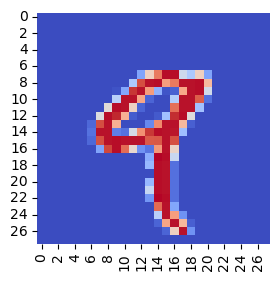

In [69]:
plt.figure(figsize=(3, 3))
sns.heatmap(data, cmap="coolwarm", annot=False, cbar=False)
plt.show()

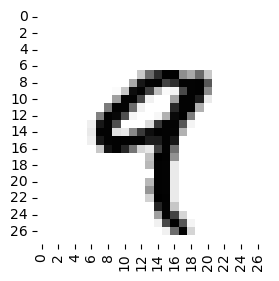

In [70]:
plt.figure(figsize=(3, 3))
sns.heatmap(data, cmap="gray_r", annot=False, cbar=False)
plt.show()

In [71]:
def sigma(x):
    s = 1/(1 + np.exp(-x))
    return s

def sigma_der(x):
    s = np.exp(-x)/(1+np.exp(-x))**2
    return s

In [72]:
def det_activations(inputs, weights, biases):
    
    activations = []
    activations.append(np.dot(weights[0],inputs) + biases[0])
    
    for i in range(1,len(biases)):

        activations.append(np.dot(weights[i],activations[i-1]) + biases[i])

    activations = [sigma(act) for act in activations]
    activations = [np.round(act, 3) for act in activations]
        
    return activations

In [206]:
inputs = np.random.rand(4)
outputs = [1, 0]

In [207]:
act = det_activations(inputs, weights, biases)
act

[array([0.181, 0.576, 0.255, 0.386, 0.325]),
 array([0.332, 0.183, 0.779, 0.586, 0.617]),
 array([0.199, 0.699, 0.532, 0.879, 0.445]),
 array([0.064, 0.116])]

In [121]:
def grad(activations, weights, biases, inputs, outputs):
    
    grad_activation = [0*act for act in activations]
    grad_bias = [0*bias for bias in biases]
    grad_weight = [0*weight for weight in weights]
    
    for k in range(len(biases[-2])):
        grad_activation[-2][k] = sum([2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * weights[-1][j][k] for j in range(len(outputs))])

    for i in range(len(biases[-3])):
        grad_activation[-3][i] = sum([2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * sum([weights[-1][j][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + 
                                    biases[-2][k]) * weights[-2][k][i] for k in range(len(biases[-2]))]) for j in range(len(outputs))])

    for m in range(len(biases[-4])):
        grad_activation[-4][m] = sum([2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * sum([weights[-1][j][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + 
                                    biases[-2][k]) * sum([weights[-2][k][i] * sigma_der(np.dot(weights[-3][i], activations[-4]) + 
                                    biases[-3][i]) * weights[-3][i][m] for i in range(len(biases[-3]))]) for k in range(len(biases[-2]))]) 
                                      for j in range(len(outputs))])
        
    
    for j in range(len(outputs)):
        grad_bias[-1][j] =  2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                biases[-1][j])

    for k in range(len(biases[-2])):
        grad_bias[-2][k] =  grad_activation[-2][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + biases[-2][k])
    
    for k in range(len(biases[-3])):
        grad_bias[-3][k] =  grad_activation[-3][k] * sigma_der(np.dot(weights[-3][k], activations[-4]) + biases[-3][k])

    for k in range(len(biases[-4])):
        grad_bias[-4][k] =  grad_activation[-4][k] * sigma_der(np.dot(weights[-4][k], inputs) + biases[-4][k])

    
    
    
    for j in range(len(outputs)):
        for k in range(len(biases[-2])):
            grad_weight[-1][j][k] =  2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * activations[-2][k]

    for k in range(len(biases[-2])):
        for i in range(len(biases[-3])):
            grad_weight[-2][k][i] =  grad_activation[-2][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + biases[-2][k]) * activations[-3][i]

    for k in range(len(biases[-3])):
        for i in range(len(biases[-4])):
            grad_weight[-3][k][i] =  grad_activation[-3][k] * sigma_der(np.dot(weights[-3][k], activations[-4]) + biases[-3][k]) * activations[-4][i]

    for k in range(len(biases[-4])):
        for i in range(len(inputs)):
            grad_weight[-4][k][i] =  grad_activation[-4][k] * sigma_der(np.dot(weights[-4][k], inputs) + biases[-4][k]) * inputs[i]
            
    
    return grad_activation, grad_weight, grad_bias

In [122]:
gr_act, gr_w, gr_b = grad(act, weights, biases, inputs, outputs)
gr_act

[array([-0.00789394, -0.00437555, -0.0019353 ,  0.01029409,  0.00151148]),
 array([-0.04615358, -0.03950162,  0.02757863,  0.00537782,  0.00303665]),
 array([-0.20608376, -0.24789261,  0.2840475 , -0.38317211,  0.26538328]),
 array([0., 0.])]

In [123]:
gr_w

[array([[-0.00148986, -0.00071958, -0.00079577, -0.00086154],
        [-0.00079516, -0.00038405, -0.00042472, -0.00045982],
        [-0.00039357, -0.00019009, -0.00021022, -0.00022759],
        [ 0.00209815,  0.00101337,  0.00112068,  0.00121329],
        [ 0.00027367,  0.00013218,  0.00014617,  0.00015825]]),
 array([[-0.00366604, -0.00810449, -0.00428858, -0.0072168 , -0.00812754],
        [-0.00267539, -0.00591446, -0.0031297 , -0.00526665, -0.00593129],
        [ 0.00111678,  0.00246885,  0.00130642,  0.00219844,  0.00247588],
        [ 0.00040459,  0.00089443,  0.0004733 ,  0.00079646,  0.00089697],
        [ 0.00024043,  0.00053151,  0.00028125,  0.00047329,  0.00053302]]),
 array([[-0.00763049, -0.01930634, -0.02284301, -0.01133672, -0.00939882],
        [-0.00758248, -0.01918487, -0.02269929, -0.01126539, -0.00933968],
        [ 0.01290716,  0.03265717,  0.03863953,  0.01917635,  0.01589834],
        [-0.02450012, -0.06198919, -0.0733448 , -0.03640018, -0.03017792],
        [ 0

In [124]:
gr_b

[array([-0.0017122 , -0.00091383, -0.0004523 ,  0.00241127,  0.00031451]),
 array([-0.01152843, -0.00841318,  0.00351188,  0.0012723 ,  0.00075606]),
 array([-0.02422376, -0.02407135,  0.04097511, -0.07777816,  0.05441705]),
 array([-0.28146449,  0.17987333])]

In [209]:
inputs = np.random.rand(4)
outputs = [1, 0.3]
cost = []

for k in range(100):
    
    activations = det_activations(inputs, weights, biases)

    cost.append(sum([(activations[-1].tolist()[i] - outputs[i])**2 for i in range(len(outputs))]))

    gr_act, gr_w, gr_b = grad(activations, weights, biases, inputs, outputs)

    weights = [w - learning_rate * gw for w, gw in zip(weights, gr_w)]
    biases = [b - learning_rate * gb for b, gb in zip(biases, gr_b)]

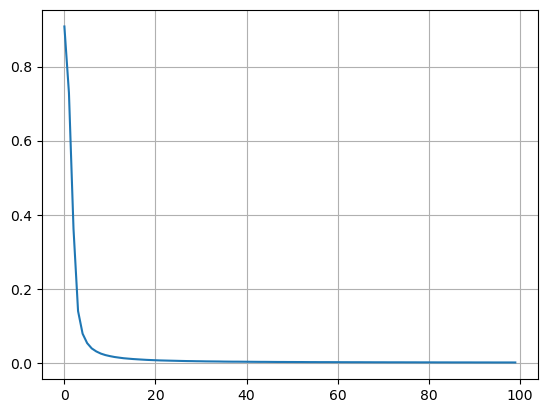

In [210]:
plt.plot(cost);
plt.grid();

In [211]:
activations[-1]

array([0.971, 0.3  ])

In [214]:
(1-0.971)**2 + (0.3 - 0.3)**2

0.0008410000000000015